# **05 - Statistical Analysis Node**

## **1. Pipeline Objective**

## **2. Dependency Management**

### **2.1 Package Installation**

In [1]:
!pip install -q pandas matplotlib seaborn scikit-learn statsmodels

### **2.2 Module Imports**

In [2]:
import json
import os
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar

### **2.3 Environment Variables**

In [ ]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
pilot_path: str = os.path.join(RESULTS_DIR, 'pilot_outputs.jsonl')
main_path: str = os.path.join(RESULTS_DIR, 'main_outputs.jsonl')

## **3. Resource Allocation**

### **3.1 Identity & Access Management (IAM)**

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **3.2 Dataset Loading (Pilot & Main)**

In [5]:
loaded_results = []
for path in [pilot_path, main_path]:
    if os.path.exists(path):
        with open(path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    loaded_results.append(json.loads(line))
        print(f"[DATASET] file='{os.path.basename(path)}' | status=LOADED")
    else:
        print(f"[DATASET] status=NOT_FOUND | path='{path}'")

print(f"[DATASET] total_rows={len(loaded_results)} | status=MERGED")

[DATASET] file='pilot_outputs.jsonl' | status=LOADED
[DATASET] file='main_outputs.jsonl' | status=LOADED
[DATASET] total_rows=3114 | status=MERGED


## **4. Feature Extraction & Preprocessing**

In [6]:
def parse_decision(raw_output: str) -> str:
    clean_text: str = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

for r in loaded_results:
    parsed = parse_decision(r["raw_output"])
    r["parsed_decision"] = parsed

    if parsed == "INVALID":
        r["logical_decision"] = "INVALID"
    elif r["position"] == "AB":
        r["logical_decision"] = 1 if parsed == "A" else 2
    else:
        r["logical_decision"] = 2 if parsed == "A" else 1

    if r["position"] == "AB":
        r["logical_human"] = 1 if r["human_preference"] == "A" else 2
    else:
        r["logical_human"] = 2 if r["human_preference"] == "A" else 1

df_all = pd.DataFrame(loaded_results)

df_all = df_all.drop_duplicates(subset=['sample_id', 'prompt_id', 'position'], keep='last')
print(f"[PREPROCESSING] rows={len(df_all)} | status=DEDUPLICATED")

invalid_rate = (len(df_all[df_all['parsed_decision'] == 'INVALID']) / len(df_all)) * 100
print(f"[METRICS] parse_failure_rate={invalid_rate:.2f}%")

df_valid = df_all[df_all['parsed_decision'] != 'INVALID'].copy()

[PREPROCESSING] rows=3114 | status=DEDUPLICATED
[METRICS] parse_failure_rate=0.00%


## **5. Statistical Compute Engine**

### **5.1 Classifier Accuracy & Kappa**

In [7]:
def bootstrap_kappa(y_true: list, y_pred: list, n_iterations: int = 1000, alpha: float = 0.05) -> tuple:
    stats = list()

    for i in range(n_iterations):
        indices = np.random.randint(0, len(y_true), len(y_true))
        score = cohen_kappa_score(np.array(y_true)[indices], np.array(y_pred)[indices])
        stats.append(score)
    lower = np.percentile(stats, (alpha/2)*100)
    upper = np.percentile(stats, (1-alpha/2)*100)

    return lower, upper

accuracy = (df_valid['logical_decision'] == df_valid['logical_human']).mean() * 100
kappa = cohen_kappa_score(list(df_valid['logical_decision']), list(df_valid['logical_human']))
kappa_ci = bootstrap_kappa(list(df_valid['logical_human']), list(df_valid['logical_decision']))

print(
    f"[METRICS] accuracy={accuracy:.2f}% | "
    f"kappa={kappa:.3f} | "
    f"kappa_ci=({kappa_ci[0]:.3f}, {kappa_ci[1]:.3f})"
)

[METRICS] accuracy=49.71% | kappa=0.000 | kappa_ci=(0.000, 0.000)


### **5.2 McNemar's Test for Bias**

In [8]:
df_pos = df_valid.pivot_table(index=['sample_id', 'prompt_id'], columns='position', values='logical_decision', aggfunc='first').dropna()
position_consistency = (df_pos['AB'] == df_pos['BA']).mean() * 100
position_flip = 100 - position_consistency

print(
    f"[METRICS] position_consistency={position_consistency:.2f}% | "
    f"flip_rate={position_flip:.2f}%"
)

b = sum((df_pos['AB'] == 1) & (df_pos['BA'] == 2))
c = sum((df_pos['AB'] == 2) & (df_pos['BA'] == 1))
table = [[0, b], [c, 0]]
result = mcnemar(table, exact=False, correction=True)

if result.pvalue < 0.05:
    print(f"[METRICS] mcnemar_pvalue={result.pvalue:.5f} | significance=TRUE")
else:
    print(f"[METRICS] mcnemar_pvalue={result.pvalue:.5f} | significance=FALSE")

first_pos_rate = (df_valid['parsed_decision'] == 'A').mean() * 100
print(f"[METRICS] first_position_preference={first_pos_rate:.2f}%")

[METRICS] position_consistency=63.52% | flip_rate=36.48%
[METRICS] mcnemar_pvalue=0.00000 | significance=TRUE
[METRICS] first_position_preference=62.20%


### **5.3 Prompt Stability Index**

In [9]:
df_prompt = df_valid[df_valid['position'] == 'AB'].pivot_table(index='sample_id', columns='prompt_id', values='logical_decision').dropna()
flip_p1_p2 = (df_prompt['P1'] != df_prompt['P2']).mean() * 100
flip_p1_p3 = (df_prompt['P1'] != df_prompt['P3']).mean() * 100
flip_p2_p3 = (df_prompt['P2'] != df_prompt['P3']).mean() * 100

print(
    f"[METRICS] flip_rate_P1_P2={flip_p1_p2:.2f}% | "
    f"flip_rate_P1_P3={flip_p1_p3:.2f}% | "
    f"flip_rate_P2_P3={flip_p2_p3:.2f}%"
)

[METRICS] flip_rate_P1_P2=15.61% | flip_rate_P1_P3=16.76% | flip_rate_P2_P3=10.02%


## **6. Reporting & Visualizations**

### **6.1 Prompt Accuracy & Position Bias**

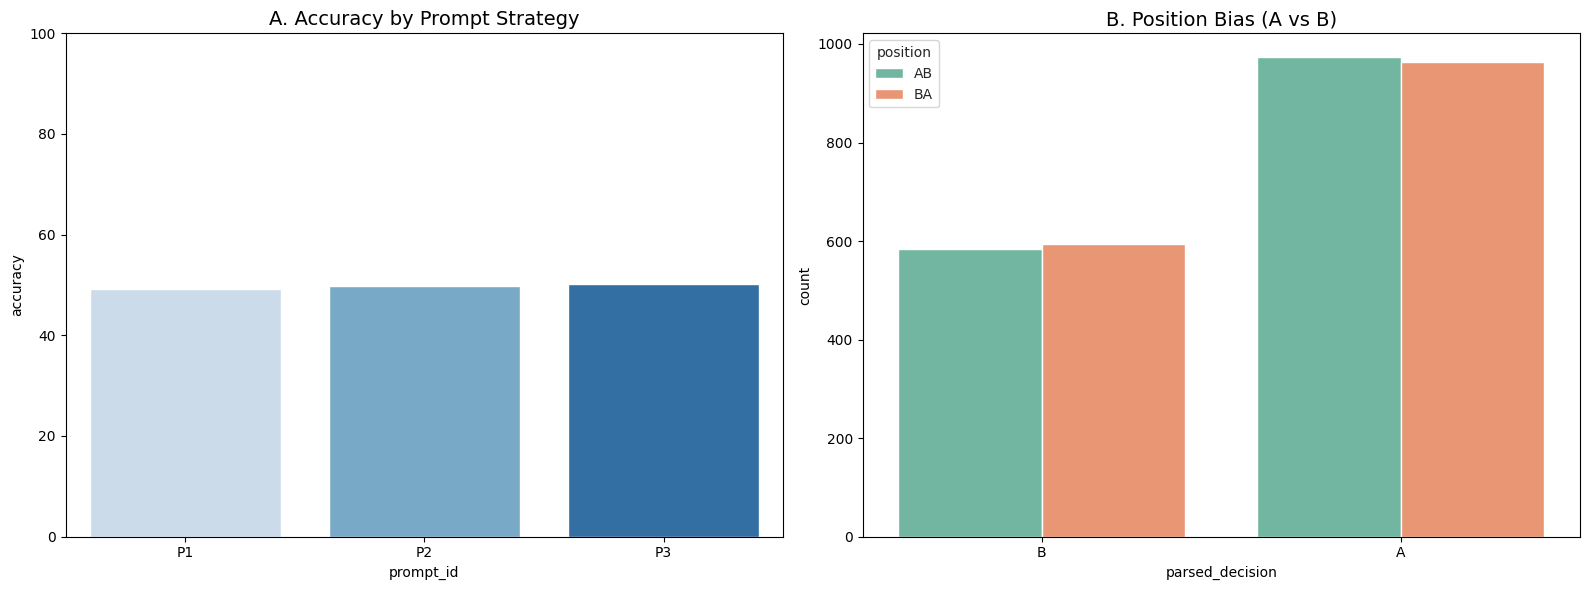

In [10]:
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 6))
sns.set_style('whitegrid')

prompt_acc = df_valid.groupby('prompt_id').apply(lambda x: (x['logical_decision'] == x['logical_human']).mean(), include_groups=False).reset_index(name='accuracy')
prompt_acc['accuracy'] = prompt_acc['accuracy'] * 100
sns.barplot(data=prompt_acc, x='prompt_id', y='accuracy', ax=axes1[0], hue='prompt_id', legend=False, palette='Blues')
axes1[0].set_title('A. Accuracy by Prompt Strategy', fontsize=14)
axes1[0].set_ylim(0, 100)

sns.countplot(data=df_valid, x='parsed_decision', hue='position', ax=axes1[1], palette='Set2')
axes1[1].set_title('B. Position Bias (A vs B)', fontsize=14)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'plot_prompt_position.png'), dpi=300)
plt.show()

### **6.2 Parsing Failure Rate & Domain Accuracy**

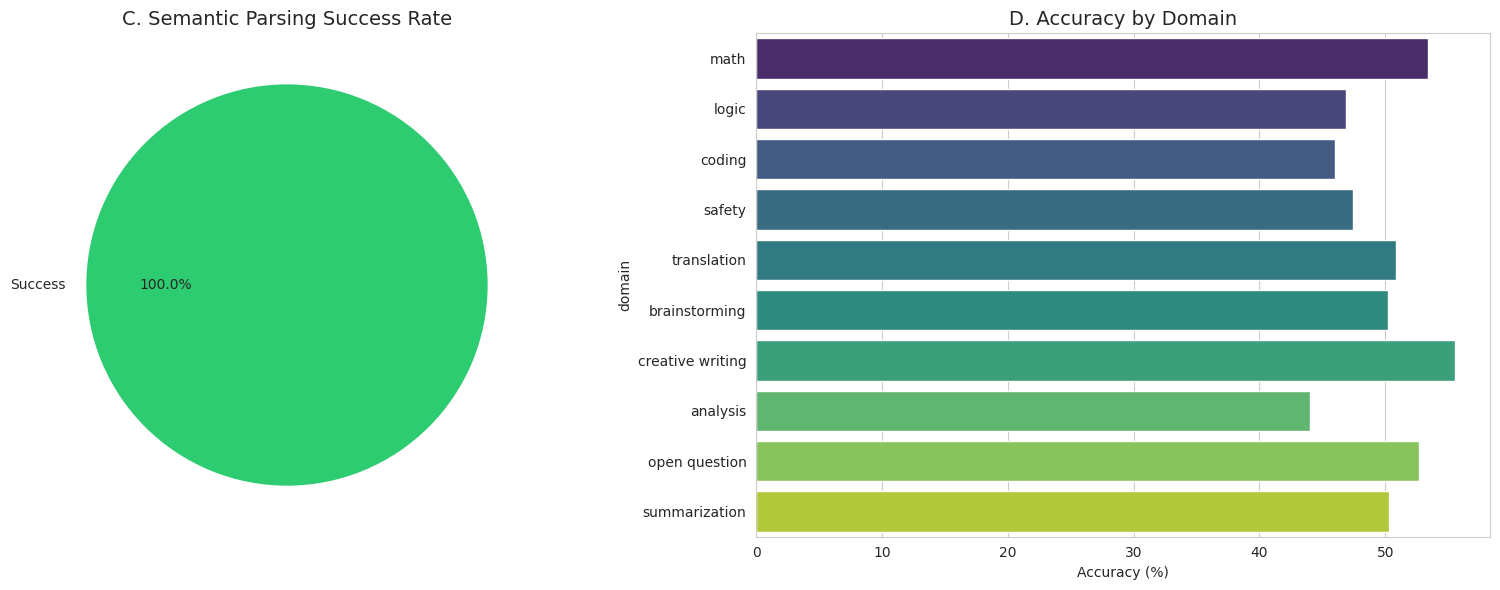

In [11]:
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))

parsing_status = df_all['parsed_decision'].apply(lambda x: 'Failed' if x == 'INVALID' else 'Success')
status_counts = parsing_status.value_counts(normalize=True) * 100
axes2[0].pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'])
axes2[0].set_title('C. Semantic Parsing Success Rate', fontsize=14)

df_valid['is_correct'] = (df_valid['logical_decision'] == df_valid['logical_human']).astype(int) * 100
sns.barplot(data=df_valid, y='domain', x='is_correct', orient='h', ax=axes2[1], hue='domain', legend=False, palette='viridis', errorbar=None)
axes2[1].set_title('D. Accuracy by Domain', fontsize=14)
axes2[1].set_xlabel('Accuracy (%)')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'plot_parsing_domain.png'), dpi=300)
plt.show()